# Sensor Fusion: Calibration, Association and Late Fusion

**Module 01 · Perception Systems** · Notebook 6 of 8

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/01_Perception/06_sensor_fusion.ipynb)

| Level | Time | Prerequisites | Standards |
|---|---|---|---|
| Intermediate | ~75 min | [03 LiDAR and point clouds](03_lidar_point_clouds.ipynb), [04 Object detection](04_object_detection.ipynb) | ISO 26262-9:2018; ISO 21448:2022 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

By the end of this notebook you will be able to:

1. Explain what sensor fusion can and cannot contribute to safety
2. Distinguish early, late and intermediate (feature-level / BEV) fusion and name current architectures
3. Project 3D LiDAR objects into a camera image using intrinsic and extrinsic calibration
4. Implement late fusion with class-agnostic Hungarian association, principled confidence combination and class-specific thresholds
5. Evaluate single-sensor vs fused detection with correct one-to-one matching, and draw data-derived conclusions
6. Quantify the effect of calibration and time-synchronisation errors on fusion

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.optimize import linear_sum_assignment
from scipy.spatial.transform import Rotation
from IPython.display import display

rng = np.random.default_rng(42)
OKABE_ITO = ['#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7', '#000000']
SENSOR_COLOURS = {'Camera': OKABE_ITO[0], 'LiDAR': OKABE_ITO[2], 'Radar': OKABE_ITO[4], 'Fusion': OKABE_ITO[6]}
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
print(f"NumPy {np.__version__}")

NumPy 2.5.4


---
## 1. Why sensor fusion?

No single sensor is sufficient in all conditions (see [02 Sensor modalities](02_sensor_modalities.ipynb)):
camera — semantics but weak in darkness and glare; LiDAR — accurate 3D but degraded by fog and spray; radar — weather-robust velocity but low resolution.

**Potential benefits**
1. **Redundancy:** if one sensor fails or is degraded, others can compensate.
2. **Complementary strengths:** the camera classifies, LiDAR measures geometry, radar measures velocity.
3. **Fewer false positives and negatives** — *if* association and decision logic are designed well.
4. **Weather robustness:** diverse physics reduces (but does not eliminate) common-cause degradation.
5. **Safety argument:** redundant, diverse sensors can support ASIL decomposition (ISO 26262-9, which requires sufficient independence) and the mitigation of performance insufficiencies (ISO 21448). Neither standard mandates fusion or a particular sensor set.

The following chart is a **qualitative** illustration of what fusion *should* achieve and what a naive fusion can actually deliver.

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements.

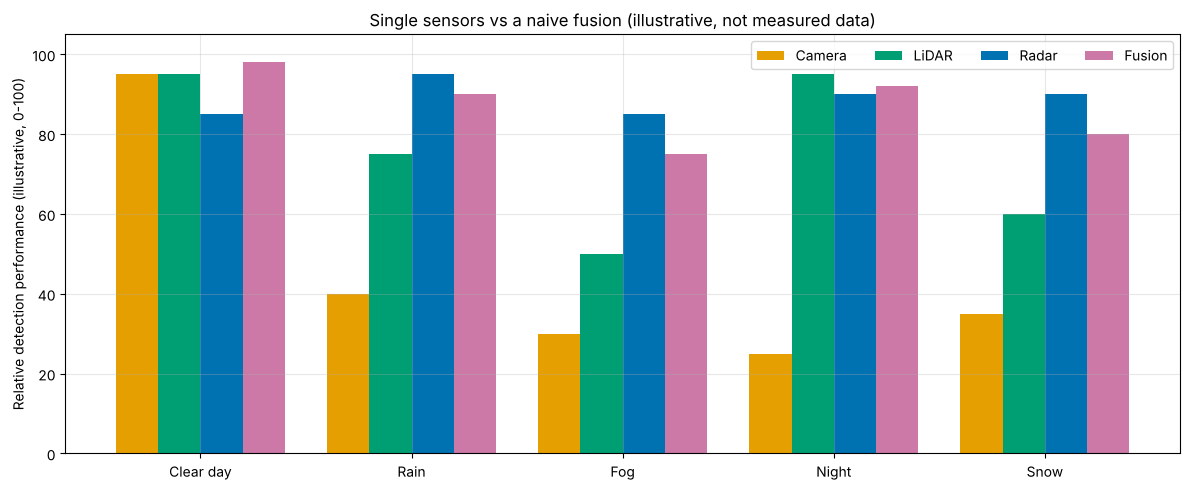

NOTE: values are illustrative teaching numbers, not measurements.
  Clear day: best single = Camera (95), fusion = 98
  Rain: best single = Radar (95), fusion = 90  <- fusion WORSE than best single sensor
  Fog: best single = Radar (85), fusion = 75  <- fusion WORSE than best single sensor
  Night: best single = LiDAR (95), fusion = 92  <- fusion WORSE than best single sensor
  Snow: best single = Radar (90), fusion = 80  <- fusion WORSE than best single sensor
In 4 of 5 conditions (Rain, Fog, Night, Snow) this naive fusion is worse than the best single sensor.
A well-designed fusion should never be worse than its best input in a given condition; it must know which sensor to trust when.


In [2]:
conditions = ['Clear day', 'Rain', 'Fog', 'Night', 'Snow']
acc = {'Camera': [95, 40, 30, 25, 35], 'LiDAR': [95, 75, 50, 95, 60],
       'Radar': [85, 95, 85, 90, 90], 'Fusion': [98, 90, 75, 92, 80]}
x = np.arange(len(conditions)); w = 0.2
fig, ax = plt.subplots(figsize=(12, 5))
for i, (s, v) in enumerate(acc.items()):
    ax.bar(x + (i - 1.5) * w, v, w, label=s, color=SENSOR_COLOURS[s])
ax.set_xticks(x); ax.set_xticklabels(conditions); ax.set_ylim(0, 105)
ax.set_ylabel('Relative detection performance (illustrative, 0-100)')
ax.set_title('Single sensors vs a naive fusion (illustrative, not measured data)'); ax.legend(ncol=4)
plt.tight_layout(); plt.show()

print("NOTE: values are illustrative teaching numbers, not measurements.")
worse = []
for j, c in enumerate(conditions):
    best_s = max(['Camera', 'LiDAR', 'Radar'], key=lambda s: acc[s][j])
    flag = acc['Fusion'][j] < acc[best_s][j]
    if flag: worse.append(c)
    print(f"  {c}: best single = {best_s} ({acc[best_s][j]}), fusion = {acc['Fusion'][j]}"
          f"{'  <- fusion WORSE than best single sensor' if flag else ''}")
print(f"In {len(worse)} of {len(conditions)} conditions ({', '.join(worse)}) this naive fusion is worse than the best single sensor.")
print("A well-designed fusion should never be worse than its best input in a given condition; it must know which sensor to trust when.")

---
## 2. Fusion architectures

### Early fusion (data level)
Raw data are combined before detection, e.g. LiDAR points painted with image colours or depth channels added to images.
**Pros:** preserves information. **Cons:** very sensitive to calibration and synchronisation; heavy computation.

### Late fusion (decision / object level)
Each sensor runs its own detector; the **object lists** are associated and combined.
```
Camera -> detections \
                      -> association -> fused object list
LiDAR  -> detections /
```
**Pros:** modular, supplier-friendly, each sensor path can be validated independently. **Cons:** information already discarded by each detector; conflicts must be resolved by rules.
Historically common in production ADAS; BEV feature-level fusion is increasingly used. **We implement late fusion below.**

### Intermediate / feature-level ("deep") fusion
Learned features from each sensor are fused inside the network. Since about 2022 the dominant design transforms all sensors into a common **bird's-eye-view (BEV)** feature map:

- **BEVFormer** (Li et al., ECCV 2022): camera-only; spatio-temporal transformer that lifts multi-camera features into BEV.
- **BEVFusion** (Liu et al., ICRA 2023): camera and LiDAR features fused in a shared BEV representation for detection and map segmentation.
- **TransFusion** (Bai et al., CVPR 2022): transformer decoder that uses LiDAR queries and attends to image features (robust to calibration error).

**Pros:** best accuracy on current benchmarks (e.g. nuScenes). **Cons:** large paired datasets, end-to-end training, harder to validate each sensor path independently — an important consideration for the safety argument.

In [3]:
fusion_comparison = pd.DataFrame({
    'Approach': ['Early fusion', 'Late fusion', 'Intermediate (BEV) fusion'],
    'Fusion level': ['Raw data', 'Object lists', 'Learned features'],
    'Calibration sensitivity': ['Very high', 'Medium', 'High (some designs tolerate errors)'],
    'Modularity / independent validation': ['Low', 'High', 'Low-medium'],
    'Typical use (as of 2026)': ['Research, some point painting', 'Production ADAS, modular stacks',
                                 'State of the art on benchmarks; increasingly in production'],
})
display(fusion_comparison)
for _, r in fusion_comparison.iterrows():
    print(f"  {r['Approach']}: fuses {r['Fusion level']}; calibration sensitivity {r['Calibration sensitivity']}; "
          f"modularity {r['Modularity / independent validation']}; use: {r['Typical use (as of 2026)']}")

,Approach,Fusion level,Calibration sensitivity,Modularity / independent validation,Typical use (as of 2026)
0,Early fusion,Raw data,Very high,Low,"Research, some point painting"
1,Late fusion,Object lists,Medium,High,"Production ADAS, modular stacks"
2,Intermediate (BEV) fusion,Learned features,High (some designs tolerate errors),Low-medium,State of the art on benchmarks; increasingly i...


  Early fusion: fuses Raw data; calibration sensitivity Very high; modularity Low; use: Research, some point painting
  Late fusion: fuses Object lists; calibration sensitivity Medium; modularity High; use: Production ADAS, modular stacks
  Intermediate (BEV) fusion: fuses Learned features; calibration sensitivity High (some designs tolerate errors); modularity Low-medium; use: State of the art on benchmarks; increasingly in production


---
## 3. Camera–LiDAR projection

To associate LiDAR objects with camera detections, the 3D boxes must be **projected into the image**. This needs:

- the **extrinsic calibration** $[R \,|\, t]$ from the LiDAR frame (x forward, y left, z up) to the camera frame (x right, y down, z forward);
- the **intrinsic matrix** $K$ of the camera (focal lengths $f_x, f_y$ and principal point $c_x, c_y$, in pixels).

$$ \tilde{\mathbf{u}} = K\,(R\,\mathbf{p}_L + \mathbf{t}), \qquad u = \tilde u_1 / \tilde u_3,\; v = \tilde u_2 / \tilde u_3 $$

Projecting the 8 corners of a 3D box and taking their min/max gives a 2D box. Intrinsics are typically estimated with Zhang's checkerboard method; extrinsics with targets or targetless methods.

> **Illustrative data:** the camera parameters (KITTI-like 1242 × 375 image) and the scene are synthetic, chosen for teaching.

In [4]:
IMG_W, IMG_H = 1242, 375
K = np.array([[720.0, 0.0, 620.0],
              [0.0, 720.0, 175.0],
              [0.0, 0.0, 1.0]])
# Axis change LiDAR (x fwd, y left, z up) -> camera (x right, y down, z fwd)
R_AXES = np.array([[0.0, -1.0, 0.0], [0.0, 0.0, -1.0], [1.0, 0.0, 0.0]])
CAM_POS_L = np.array([0.27, 0.0, -0.08])          # camera position in the LiDAR frame [m]
R_CL = R_AXES
t_CL = -R_CL @ CAM_POS_L
LIDAR_H = 1.73                                     # LiDAR height above ground [m]

def box_corners(c, size, yaw):
    """8 corners of a 3D box (LiDAR frame). c = centre, size = (l, w, h), yaw about z."""
    l, w, h = size
    xs = np.array([1, 1, -1, -1, 1, 1, -1, -1]) * l / 2
    ys = np.array([1, -1, -1, 1, 1, -1, -1, 1]) * w / 2
    zs = np.array([-1, -1, -1, -1, 1, 1, 1, 1]) * h / 2
    Rz = Rotation.from_euler('z', yaw).as_matrix()
    return (Rz @ np.vstack([xs, ys, zs])).T + c

def project_box(corners_L, R=R_CL, t=t_CL, K=K):
    """Project 3D corners into the image; return clipped [x1, y1, x2, y2] or None if behind / outside."""
    pc = corners_L @ R.T + t
    if np.any(pc[:, 2] <= 0.1):
        return None
    uv = (pc @ K.T)[:, :2] / pc[:, 2:3]
    x1, y1 = uv.min(0); x2, y2 = uv.max(0)
    x1, x2 = np.clip([x1, x2], 0, IMG_W); y1, y2 = np.clip([y1, y2], 0, IMG_H)
    return [float(x1), float(y1), float(x2), float(y2)] if (x2 - x1 > 1 and y2 - y1 > 1) else None

g = -LIDAR_H
SCENE_3D = [  # class, centre (x, y, z) in LiDAR frame, size (l, w, h), yaw
    ('car',        (15.0,  0.0, g + 0.75), (4.2, 1.8, 1.5), 0.0),
    ('car',        (25.0, -3.5, g + 0.75), (4.5, 1.9, 1.5), 0.05),
    ('truck',      (35.0,  4.0, g + 1.6),  (8.0, 2.5, 3.2), 0.0),
    ('pedestrian', (40.0, -10.0, g + 0.875),(0.5, 0.6, 1.75), 0.0),
]
ground_truth = []
for cls, c, s, yaw in SCENE_3D:
    b = project_box(box_corners(np.array(c), s, yaw))
    ground_truth.append({'class': cls, 'bbox': b})
gt_df = pd.DataFrame([{'class': gt['class'], 'distance (m)': c[0], 'x1': round(gt['bbox'][0]), 'y1': round(gt['bbox'][1]),
                       'x2': round(gt['bbox'][2]), 'y2': round(gt['bbox'][3]),
                       'height (px)': round(gt['bbox'][3] - gt['bbox'][1])} for gt, (_, c, _, _) in zip(ground_truth, SCENE_3D)])
display(gt_df)
for _, r in gt_df.iterrows():
    print(f"  {r['class']:10s} at {r['distance (m)']:4.0f} m -> image box height {r['height (px)']} px")

,class,distance (m),x1,y1,x2,y2,height (px)
0,car,15.0,569,181,671,269,88
1,car,25.0,685,179,766,228,49
2,truck,35.0,497,139,569,214,75
3,pedestrian,40.0,795,173,808,205,32


  car        at   15 m -> image box height 88 px
  car        at   25 m -> image box height 49 px
  truck      at   35 m -> image box height 75 px
  pedestrian at   40 m -> image box height 32 px


### Simulated detections

- **Camera:** detects both cars, the pedestrian with modest confidence (0.65), the truck but **misclassifies it as "car"** (0.60), and produces a **bicycle false positive** (0.45).
- **LiDAR:** detects both cars and the truck in 3D, but **misses the pedestrian** at 40 m (too few points, cf. notebook 03). Its 3D boxes are projected into the image with the calibration above.

> **Illustrative data:** synthetic detections, chosen for teaching.

In [5]:
def jitter(b, s=3.0):
    return [float(v) for v in np.array(b) + rng.normal(0, s, 4)]

camera_detections = [
    {'bbox': jitter(ground_truth[0]['bbox']), 'confidence': 0.92, 'class': 'car'},
    {'bbox': jitter(ground_truth[1]['bbox']), 'confidence': 0.88, 'class': 'car'},
    {'bbox': jitter(ground_truth[2]['bbox']), 'confidence': 0.60, 'class': 'car'},          # truck misclassified
    {'bbox': jitter(ground_truth[3]['bbox'], 1.0), 'confidence': 0.65, 'class': 'pedestrian'},
    {'bbox': [900.0, 120.0, 960.0, 200.0], 'confidence': 0.45, 'class': 'bicycle'},         # false positive
]
# LiDAR: 3D detections with small position noise, projected with the (true) calibration
lidar_3d = [(cls, np.array(c) + rng.normal(0, 0.1, 3), s, yaw, conf)
            for (cls, c, s, yaw), conf in zip(SCENE_3D[:3], [0.95, 0.90, 0.85])]

def lidar_to_image(lidar_3d, R=R_CL, t=t_CL):
    out = []
    for cls, c, s, yaw, conf in lidar_3d:
        b = project_box(box_corners(c, s, yaw), R, t)
        if b is not None:
            out.append({'bbox': b, 'confidence': conf, 'class': cls})
    return out

lidar_detections = lidar_to_image(lidar_3d)
print("Camera detections:")
for d in camera_detections:
    print(f"  {d['class']:10s} conf {d['confidence']:.2f}  {[round(v) for v in d['bbox']]}")
print("LiDAR detections (projected):")
for d in lidar_detections:
    print(f"  {d['class']:10s} conf {d['confidence']:.2f}  {[round(v) for v in d['bbox']]}")

Camera detections:
  car        conf 0.92  [570, 178, 674, 272]
  car        conf 0.88  [679, 175, 766, 227]
  car        conf 0.60  [497, 136, 572, 216]
  pedestrian conf 0.65  [795, 174, 808, 204]
  bicycle    conf 0.45  [900, 120, 960, 200]
LiDAR detections (projected):
  car        conf 0.95  [574, 178, 677, 264]
  car        conf 0.90  [686, 181, 766, 230]
  truck      conf 0.85  [498, 140, 569, 215]


---
## 4. Late fusion

1. **Associate** camera and LiDAR detections by IoU with the Hungarian algorithm — **class-agnostic**, so that a car/truck disagreement can be detected and resolved instead of producing two objects.
2. **Combine matched pairs:** confidence-weighted box; class from the more confident sensor; confidence by **noisy-OR**, $c = 1 - (1 - c_{cam})(1 - c_{lid})$, so that agreement between (approximately) independent sensors *raises* confidence. This assumes conditional independence and calibrated confidences — both must be checked.
3. **Unmatched detections:** keep if above a threshold. A single class-agnostic threshold (e.g. 0.7) is unsafe for VRUs; we compare it with **class-specific thresholds** (pedestrian/bicycle 0.3).

In [6]:
def iou(a, b):
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

def associate(cam, lid, iou_thr=0.3, class_aware=False):
    """Hungarian association on IoU. Returns matches, unmatched camera idx, unmatched LiDAR idx."""
    if not cam or not lid:
        return [], list(range(len(cam))), list(range(len(lid)))
    M = np.array([[iou(c['bbox'], l['bbox']) if (not class_aware or c['class'] == l['class']) else 0.0
                   for l in lid] for c in cam])
    rows, cols = linear_sum_assignment(-M)
    matches = [(i, j) for i, j in zip(rows, cols) if M[i, j] >= iou_thr]
    mc = {i for i, _ in matches}; ml = {j for _, j in matches}
    return matches, [i for i in range(len(cam)) if i not in mc], [j for j in range(len(lid)) if j not in ml]

def late_fusion(cam, lid, mode='safety'):
    """mode='naive': class-aware matching, averaged confidence, one threshold 0.7 for unmatched.
       mode='safety': class-agnostic matching, noisy-OR, class-specific thresholds for unmatched."""
    naive = mode == 'naive'
    matches, um_c, um_l = associate(cam, lid, class_aware=naive)
    fused = []
    for i, j in matches:
        c, l = cam[i], lid[j]
        wc = c['confidence'] / (c['confidence'] + l['confidence'])
        box = [wc * a + (1 - wc) * b for a, b in zip(c['bbox'], l['bbox'])]
        if naive:
            conf = 0.5 * (c['confidence'] + l['confidence'])
            cls = c['class']
        else:
            conf = 1 - (1 - c['confidence']) * (1 - l['confidence'])   # assumes conditional independence
            cls = c['class'] if c['confidence'] >= l['confidence'] else l['class']
        note = '' if c['class'] == l['class'] else f" (conflict: cam={c['class']}, lidar={l['class']})"
        fused.append({'bbox': box, 'confidence': conf, 'class': cls, 'source': 'fused' + note})
    thr = (lambda cls: 0.7) if naive else (lambda cls: {'pedestrian': 0.3, 'bicycle': 0.3}.get(cls, 0.7))
    for i in um_c:
        if cam[i]['confidence'] >= thr(cam[i]['class']):
            fused.append({**cam[i], 'source': 'camera_only'})
    for j in um_l:
        if lid[j]['confidence'] >= thr(lid[j]['class']):
            fused.append({**lid[j], 'source': 'lidar_only'})
    return fused

fused_naive = late_fusion(camera_detections, lidar_detections, 'naive')
fused_safe = late_fusion(camera_detections, lidar_detections, 'safety')
for name, fz in [('Naive fusion', fused_naive), ('Safety-aware fusion', fused_safe)]:
    print(f"{name}: {len(fz)} objects")
    for d in fz:
        print(f"  {d['class']:10s} conf {d['confidence']:.3f}  source: {d['source']}")

Naive fusion: 3 objects
  car        conf 0.935  source: fused
  car        conf 0.890  source: fused
  truck      conf 0.850  source: lidar_only
Safety-aware fusion: 5 objects
  car        conf 0.996  source: fused
  car        conf 0.988  source: fused
  truck      conf 0.940  source: fused (conflict: cam=car, lidar=truck)
  pedestrian conf 0.650  source: camera_only
  bicycle    conf 0.450  source: camera_only


,Method,Precision,Recall,F1,Pedestrian found,Detections
0,Camera,0.6,0.75,0.667,True,5
1,LiDAR,1.0,0.75,0.857,False,3
2,Naive fusion,1.0,0.75,0.857,False,3
3,Safety-aware fusion,0.8,1.00,0.889,True,5


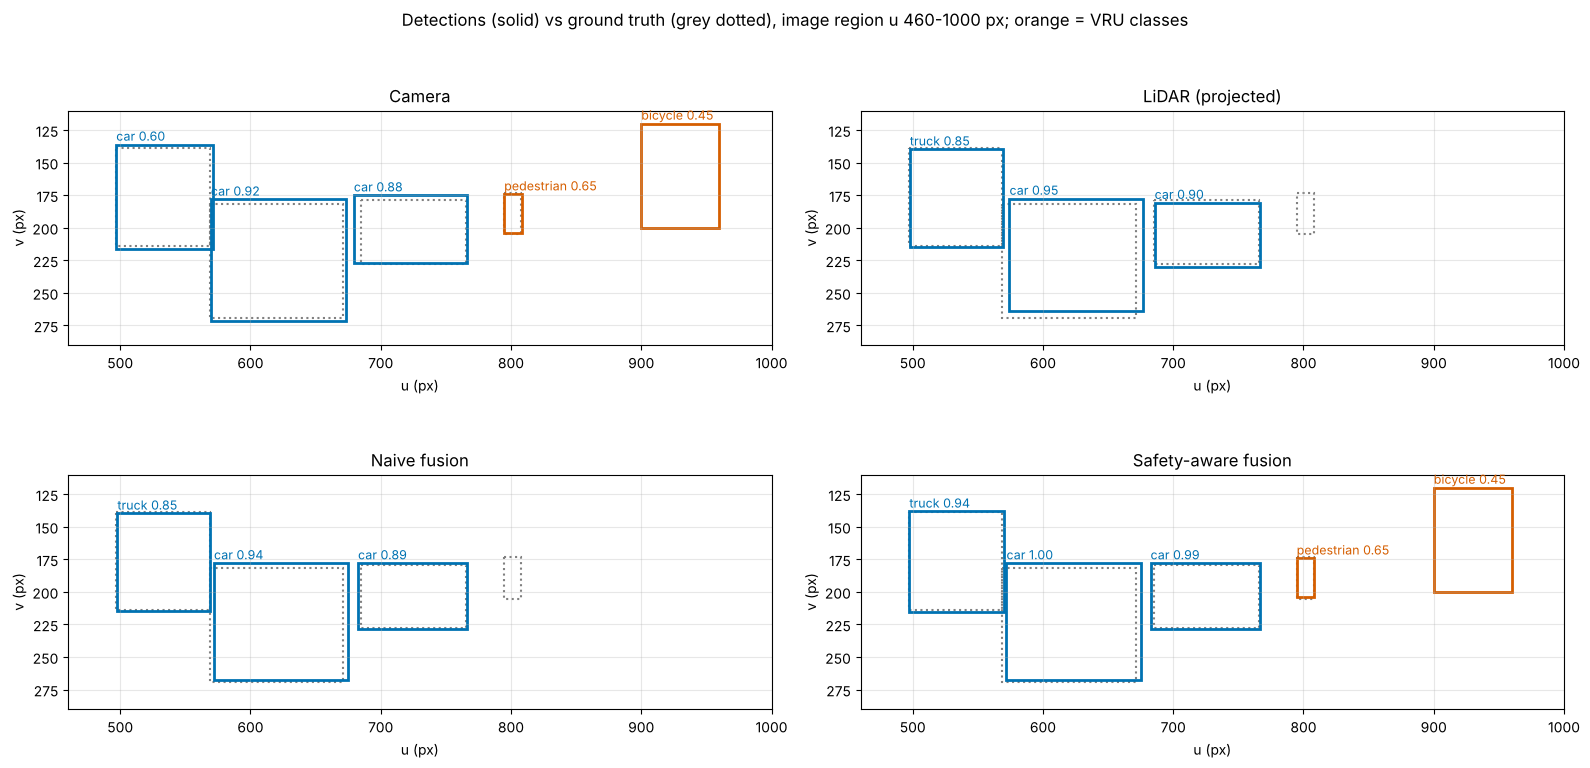

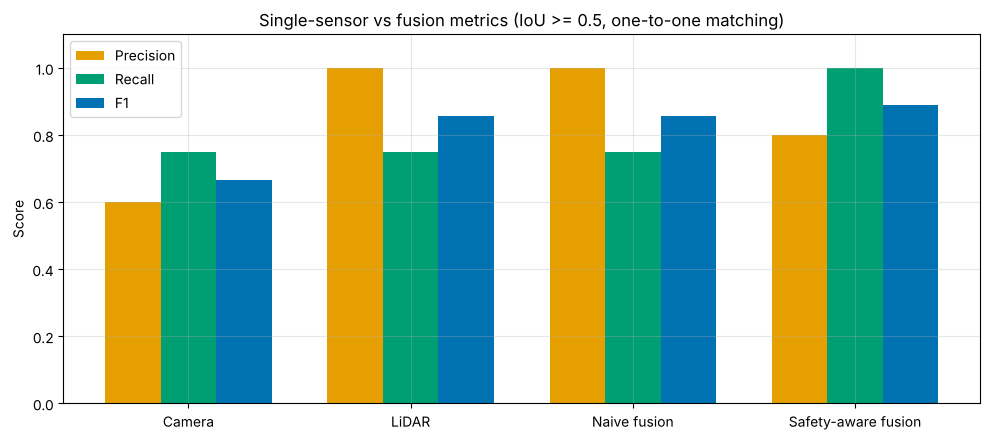

--- Metrics (text summary) ---
  Camera               P=0.60 R=0.75 F1=0.67 pedestrian found: True
  LiDAR                P=1.00 R=0.75 F1=0.86 pedestrian found: False
  Naive fusion         P=1.00 R=0.75 F1=0.86 pedestrian found: False
  Safety-aware fusion  P=0.80 R=1.00 F1=0.89 pedestrian found: True
Highest F1: Safety-aware fusion (0.89).
Naive fusion DROPS the real pedestrian (camera-only, conf 0.65 < 0.7) together with the bicycle false positive.
Safety-aware fusion keeps the pedestrian via a lower VRU threshold - at the price of also keeping the bicycle false positive.
Class conflict resolved: camera said 'car', LiDAR said 'truck' -> 'truck' (more confident sensor).
Fusion does not automatically improve results: the association and decision rules determine the outcome.


In [7]:
def compute_metrics(detections, ground_truth, iou_thr=0.5):
    """Precision, recall, F1 with one-to-one, class-aware matching (highest confidence first)."""
    used, tp = set(), 0
    for det in sorted(detections, key=lambda d: -d['confidence']):
        best, best_j = 0.0, None
        for j, gt in enumerate(ground_truth):
            if j in used or det['class'] != gt['class']:
                continue
            v = iou(det['bbox'], gt['bbox'])
            if v > best:
                best, best_j = v, j
        if best >= iou_thr:
            tp += 1; used.add(best_j)
    p = tp / len(detections) if detections else 0.0
    r = tp / len(ground_truth) if ground_truth else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0), used

methods = {'Camera': camera_detections, 'LiDAR': lidar_detections,
           'Naive fusion': fused_naive, 'Safety-aware fusion': fused_safe}
rows = []
for name, dets in methods.items():
    p, r, f1, used = compute_metrics(dets, ground_truth)
    ped_found = any(ground_truth[j]['class'] == 'pedestrian' for j in used)
    rows.append({'Method': name, 'Precision': round(p, 3), 'Recall': round(r, 3), 'F1': round(f1, 3),
                 'Pedestrian found': ped_found, 'Detections': len(dets)})
metrics_df = pd.DataFrame(rows); display(metrics_df)

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
panels = [('Camera', camera_detections), ('LiDAR (projected)', lidar_detections),
          ('Naive fusion', fused_naive), ('Safety-aware fusion', fused_safe)]
for ax, (ttl, dets) in zip(axes.ravel(), panels):
    ax.set_xlim(460, 1000); ax.set_ylim(290, 110); ax.set_aspect('equal')
    for gt in ground_truth:
        x1, y1, x2, y2 = gt['bbox']
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ls=':', lw=1.5, edgecolor='grey'))
    for d in dets:
        x1, y1, x2, y2 = d['bbox']
        col = OKABE_ITO[5] if d['class'] in ('pedestrian', 'bicycle') else OKABE_ITO[4]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=2, edgecolor=col))
        ax.text(x1, y1 - 3, f"{d['class']} {d['confidence']:.2f}", fontsize=9, color=col)
    ax.set_title(ttl); ax.set_xlabel('u (px)'); ax.set_ylabel('v (px)')
fig.suptitle('Detections (solid) vs ground truth (grey dotted), image region u 460-1000 px; orange = VRU classes')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
xx = np.arange(len(metrics_df)); w = 0.25
for k, (m, col) in enumerate(zip(['Precision', 'Recall', 'F1'], [OKABE_ITO[0], OKABE_ITO[2], OKABE_ITO[4]])):
    ax.bar(xx + (k - 1) * w, metrics_df[m], w, label=m, color=col)
ax.set_xticks(xx); ax.set_xticklabels(metrics_df['Method']); ax.set_ylim(0, 1.1); ax.set_ylabel('Score')
ax.set_title('Single-sensor vs fusion metrics (IoU >= 0.5, one-to-one matching)'); ax.legend()
plt.tight_layout(); plt.show()

print("--- Metrics (text summary) ---")
for r in rows:
    print(f"  {r['Method']:20s} P={r['Precision']:.2f} R={r['Recall']:.2f} F1={r['F1']:.2f} pedestrian found: {r['Pedestrian found']}")
best = metrics_df.loc[metrics_df['F1'].idxmax()]
ties = metrics_df[metrics_df['F1'] == best['F1']]['Method'].tolist()
print(f"Highest F1: {', '.join(ties)} ({best['F1']:.2f}).")
naive_ped = metrics_df.set_index('Method').loc['Naive fusion', 'Pedestrian found']
safe_ped = metrics_df.set_index('Method').loc['Safety-aware fusion', 'Pedestrian found']
if not naive_ped:
    print("Naive fusion DROPS the real pedestrian (camera-only, conf 0.65 < 0.7) together with the bicycle false positive.")
if safe_ped:
    print("Safety-aware fusion keeps the pedestrian via a lower VRU threshold"
          + (" - at the price of also keeping the bicycle false positive." if any(d['class'] == 'bicycle' for d in fused_safe) else "."))
conflicts = [d for d in fused_safe if 'conflict' in d['source']]
for d in conflicts:
    cam_cls, lid_cls = [t.split('=')[1] for t in d['source'].split('(')[1].rstrip(')').split(', ')]
    print(f"Class conflict resolved: camera said '{cam_cls}', LiDAR said '{lid_cls}' -> '{d['class']}' (more confident sensor).")
print("Fusion does not automatically improve results: the association and decision rules determine the outcome.")

---
## 5. Calibration and time-synchronisation errors

### Extrinsic calibration error
We rotate the LiDAR→camera extrinsics by a small **yaw error** and re-project the LiDAR boxes. Note that *unmatched* LiDAR-only boxes are also mis-projected — a realistic effect of extrinsic error.

,yaw error (deg),mean box shift (px),matched pairs,precision,recall,F1,F1 LiDAR-only (projected)
0,0.0,0.0,3,0.800,1.00,0.889,0.857
1,0.5,6.4,3,0.800,1.00,0.889,0.857
2,1.0,12.7,3,0.800,1.00,0.889,0.857
3,2.0,25.4,3,0.800,1.00,0.889,0.000
4,3.0,38.2,2,0.667,1.00,0.800,0.000
5,4.0,50.9,0,0.429,0.75,0.545,0.000
6,5.0,63.6,0,0.429,0.75,0.545,0.000
7,6.0,76.3,1,0.500,0.75,0.600,0.000


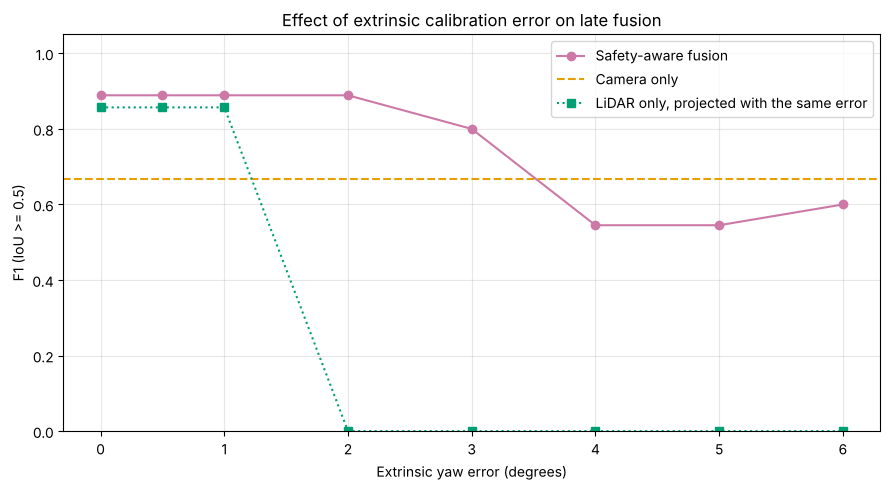

--- Calibration sweep (text summary) ---
  0.00 deg: boxes shift 0.0 px, 3 matched pairs, fusion F1 = 0.89, projected LiDAR-only F1 = 0.86
  0.50 deg: boxes shift 6.4 px, 3 matched pairs, fusion F1 = 0.89, projected LiDAR-only F1 = 0.86
  1.00 deg: boxes shift 12.7 px, 3 matched pairs, fusion F1 = 0.89, projected LiDAR-only F1 = 0.86
  2.00 deg: boxes shift 25.4 px, 3 matched pairs, fusion F1 = 0.89, projected LiDAR-only F1 = 0.00
  3.00 deg: boxes shift 38.2 px, 2 matched pairs, fusion F1 = 0.80, projected LiDAR-only F1 = 0.00
  4.00 deg: boxes shift 50.9 px, 0 matched pairs, fusion F1 = 0.55, projected LiDAR-only F1 = 0.00
  5.00 deg: boxes shift 63.6 px, 0 matched pairs, fusion F1 = 0.55, projected LiDAR-only F1 = 0.00
  6.00 deg: boxes shift 76.3 px, 1 matched pairs, fusion F1 = 0.60, projected LiDAR-only F1 = 0.00
  Camera-only F1 = 0.67. Fusion falls below camera-only from a yaw error of 4.0 deg.
  1 deg at f = 720 px shifts boxes by ~13 px - online calibration monitoring is a sa

In [8]:
yaw_errors = [0.0, 0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0]
rows = []
for e in yaw_errors:
    R_err = Rotation.from_euler('y', e, degrees=True).as_matrix() @ R_CL      # yaw about the camera's vertical axis
    lid_e = lidar_to_image(lidar_3d, R_err, -R_err @ CAM_POS_L)
    fz = late_fusion(camera_detections, lid_e, 'safety')
    p, r, f1, _ = compute_metrics(fz, ground_truth)
    f1_lid = compute_metrics(lid_e, ground_truth)[2]
    n_match = len(associate(camera_detections, lid_e)[0])
    shift = np.mean([abs(a['bbox'][0] - b['bbox'][0]) for a, b in zip(lid_e, lidar_detections)]) if lid_e else np.nan
    rows.append({'yaw error (deg)': e, 'mean box shift (px)': round(shift, 1), 'matched pairs': n_match,
                 'precision': round(p, 3), 'recall': round(r, 3), 'F1': round(f1, 3), 'F1 LiDAR-only (projected)': round(f1_lid, 3)})
calib_df = pd.DataFrame(rows); display(calib_df)
cam_f1 = metrics_df.set_index('Method').loc['Camera', 'F1']

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(calib_df['yaw error (deg)'], calib_df['F1'], 'o-', color=SENSOR_COLOURS['Fusion'], label='Safety-aware fusion')
ax.axhline(cam_f1, color=SENSOR_COLOURS['Camera'], ls='--', label='Camera only')
ax.plot(calib_df['yaw error (deg)'], calib_df['F1 LiDAR-only (projected)'], 's:', color=SENSOR_COLOURS['LiDAR'], label='LiDAR only, projected with the same error')
ax.set_xlabel('Extrinsic yaw error (degrees)'); ax.set_ylabel('F1 (IoU >= 0.5)'); ax.set_ylim(0, 1.05)
ax.set_title('Effect of extrinsic calibration error on late fusion'); ax.legend()
plt.tight_layout(); plt.show()

print("--- Calibration sweep (text summary) ---")
for r in rows:
    print(f"  {r['yaw error (deg)']:4.2f} deg: boxes shift {r['mean box shift (px)']} px, {r['matched pairs']} matched pairs, "
          f"fusion F1 = {r['F1']:.2f}, projected LiDAR-only F1 = {r['F1 LiDAR-only (projected)']:.2f}")
below = [r['yaw error (deg)'] for r in rows if r['F1'] < cam_f1]
print(f"  Camera-only F1 = {cam_f1:.2f}. Fusion falls below camera-only from a yaw error of "
      f"{min(below) if below else 'more than ' + str(yaw_errors[-1])} deg.")
print(f"  1 deg at f = {K[0,0]:.0f} px shifts boxes by ~{K[0,0]*np.tan(np.deg2rad(1)):.0f} px - online calibration monitoring is a safety mechanism.")

### Time synchronisation

If camera and LiDAR sample the scene at different instants, a moving object appears at different positions. The error is simply $\Delta x = v_{rel}\,\Delta t$. Production systems use hardware time synchronisation (e.g. PTP / gPTP, IEEE 802.1AS), trigger cameras when the LiDAR sweeps past their field of view (as in nuScenes), and **motion-compensate** the points; residual offsets should be a few milliseconds.

In [9]:
dts = np.array([1, 5, 10, 33, 50, 100]) / 1000.0
v_rel = np.array([5, 14, 30])            # m/s: cyclist, urban traffic, oncoming motorway traffic (~108 km/h)
tbl = pd.DataFrame({f'{v} m/s': np.round(v * dts, 3) for v in v_rel}, index=[f'{dt*1000:.0f} ms' for dt in dts])
display(tbl)
print("Position error (m) = relative speed x time offset:")
for dt in dts:
    print(f"  {dt*1000:5.0f} ms: " + ", ".join(f"{v} m/s -> {v*dt:5.2f} m" for v in v_rel))
print(f"A 100 ms offset at 30 m/s is a {30*0.1:.1f} m error - larger than a car's width.")

,5 m/s,14 m/s,30 m/s
1 ms,0.005,0.014,0.03
5 ms,0.025,0.070,0.15
10 ms,0.050,0.140,0.30
33 ms,0.165,0.462,0.99
50 ms,0.250,0.700,1.50
100 ms,0.500,1.400,3.00


Position error (m) = relative speed x time offset:
      1 ms: 5 m/s ->  0.01 m, 14 m/s ->  0.01 m, 30 m/s ->  0.03 m
      5 ms: 5 m/s ->  0.03 m, 14 m/s ->  0.07 m, 30 m/s ->  0.15 m
     10 ms: 5 m/s ->  0.05 m, 14 m/s ->  0.14 m, 30 m/s ->  0.30 m
     33 ms: 5 m/s ->  0.17 m, 14 m/s ->  0.46 m, 30 m/s ->  0.99 m
     50 ms: 5 m/s ->  0.25 m, 14 m/s ->  0.70 m, 30 m/s ->  1.50 m
    100 ms: 5 m/s ->  0.50 m, 14 m/s ->  1.40 m, 30 m/s ->  3.00 m
A 100 ms offset at 30 m/s is a 3.0 m error - larger than a car's width.


### Other challenges
- **Conflicting information:** class conflicts (car vs truck) and existence conflicts (camera sees, LiDAR does not) need explicit, verified rules.
- **Sensor degradation:** dirty lenses, water, mud, ice — the system must detect degradation and down-weight or exclude the sensor.
- **Computational cost:** fusion must fit the latency budget (order of 100 ms end to end).
- **Common causes:** fusion of two sensors that fail together (e.g. both blinded by spray) gives no redundancy.

---
## Exercise: design a fusion strategy

**Scenario:** an L4 campus shuttle with 4 cameras (front, rear, left, right), 1 roof LiDAR (360°) and 2 radars (front, rear).

1. Which fusion approach would you use (early / late / intermediate) and why?
2. How do you detect and handle sensor failures and degradation?
3. How do you resolve class and existence conflicts — in particular for pedestrians?
4. How do you validate the fusion, including calibration and time-sync tolerances?

In [10]:
your_strategy = {
    'fusion_approach': '',      # early / late / intermediate
    'reasoning': '',
    'failure_handling': '',
    'conflict_resolution': '',
    'validation_plan': '',
}
print("Consider: real-time constraints; safety criticality (ASIL from your HARA); sensor failure modes;"
      " environmental conditions; independence of sensor paths.")
# Sample answer (uncomment to see)
# sample_answer = {
#     'fusion_approach': 'BEV feature fusion for performance plus an independent late-fusion/LiDAR-cluster safety path',
#     'reasoning': 'Best accuracy from BEV fusion; an independent, simpler path supports the safety argument (diversity).',
#     'failure_handling': 'Sensor health monitoring, calibration monitoring, degraded modes, minimal-risk manoeuvre',
#     'conflict_resolution': 'Class-agnostic association; VRU-preferring rules; low single-sensor thresholds for VRUs + tracking confirmation',
#     'validation_plan': 'Per-class/per-distance metrics on nuScenes-like data + campus data, calibration/time-offset sweeps, scenario simulation, field tests',
# }
# print(sample_answer)

Consider: real-time constraints; safety criticality (ASIL from your HARA); sensor failure modes; environmental conditions; independence of sensor paths.


---
## Safety perspective

- **ISO 26262-9:2018** allows **ASIL decomposition** of a safety requirement onto redundant elements (e.g. D → B(D) + B(D)) only if the elements are **sufficiently independent** (dependent-failure analysis). Shared calibration, shared time base, shared compute or a shared learned BEV backbone are dependencies that must be analysed.
- **ISO 21448:2022:** fusion is a measure against **performance insufficiencies** (one sensor's limitation is covered by another). Calibration drift, time offsets and association rules are themselves potential sources of insufficiency and triggering conditions (e.g. fast crossing traffic exposes time offsets).
- **ISO/PAS 8800:2024:** learned fusion (BEVFusion-type) is an AI element whose data coverage (all sensor-degradation combinations) must be argued.
- The pedestrian example shows that decision thresholds are **safety requirements** — derive them from the hazard analysis, per class.

Continue with: [07 Multi-object tracking](07_multi_object_tracking.ipynb) · [03_Functional_Safety_ISO26262/01 — ISO 26262 fundamentals](../03_Functional_Safety_ISO26262/01_iso26262_fundamentals.ipynb) · [04_SOTIF_ISO21448/01 — SOTIF fundamentals](../04_SOTIF_ISO21448/01_sotif_fundamentals.ipynb).

## Key takeaways

- Fusion helps only if association and decision logic are right: in the example, naive fusion ties LiDAR-only on F1 and silently drops the real pedestrian.
- Use class-agnostic association to expose class conflicts; combine agreeing confidences with noisy-OR (assuming independence and calibration) rather than averaging.
- Single-sensor thresholds must be class-specific: a lower VRU threshold recovers the pedestrian at the cost of a false positive — a trade-off to resolve with tracking and further evidence.
- Camera–LiDAR association requires intrinsics K and extrinsics [R|t]; 1° of yaw error shifts boxes by ~13 px at f = 720 px and quickly breaks association.
- Time offsets translate into position errors v·Δt: 100 ms at 30 m/s is 3 m; hardware sync (PTP) and motion compensation are required.
- BEV feature fusion (BEVFormer, BEVFusion, TransFusion) leads benchmarks, but late fusion keeps sensor paths independently verifiable — relevant to ISO 26262-9 decomposition.

## Self-assessment

1. What makes late fusion attractive for modular, supplier-based production systems?
2. A camera reports 'car' with 0.85, LiDAR reports 'truck' with 0.90 for the same object. How should a late-fusion system resolve this, and why must association be class-agnostic to notice the conflict?
3. Two independent sensors detect an object with confidences 0.6 and 0.7. What is the noisy-OR fused confidence, and what assumptions does it rely on?
4. From the calibration sweep: beyond which yaw error is fusion worse than camera-only? Why do LiDAR-only objects also suffer?
5. Name two failure modes that sensor fusion cannot solve.
6. How can redundant, diverse sensors support an ASIL decomposition argument under ISO 26262-9, and which hazards does ISO 21448 (SOTIF) address that ISO 26262 does not?

<details>
<summary>Show answers</summary>

1. Each sensor supplier delivers a validated object list; interfaces are simple; paths can be tested and replaced independently, and the rules are explainable.
2. Match on geometry (IoU) regardless of class, then resolve the class with a rule (e.g. the more confident sensor, or a class-confusion model) — here 'truck'. With class-aware matching the two detections never match and two separate objects are emitted.
3. 1 − (1 − 0.6)(1 − 0.7) = 0.88. It assumes the sensors' errors are conditionally independent and that both confidences are calibrated probabilities.
4. Read it from the printed sweep: in this example fusion drops below camera-only at about 4°, while the projected LiDAR boxes alone already fail IoU ≥ 0.5 at 2°. The fused boxes degrade more slowly because the camera contributes half of each box. The extrinsic error moves every projected LiDAR box, including unmatched LiDAR-only ones, away from its true image position.
5. Common-cause degradation of all sensors (heavy snow/ice, spray, shared power or compute failure) and objects outside every sensor's capability (e.g. an unusual object none of the detectors was trained on, or occluded for all sensors).
6. If the redundant paths are sufficiently independent (shown by dependent-failure analysis), a requirement can be decomposed into lower-ASIL requirements on each path. ISO 21448 addresses hazards from performance insufficiencies and triggering conditions without any fault, e.g. a camera and LiDAR both missing a dark-clad pedestrian at night.

</details>

## References

1. ISO 26262-9:2018. *Road vehicles — Functional safety — Part 9: ASIL-oriented and safety-oriented analyses.* https://www.iso.org/standard/68391.html
2. ISO 21448:2022. *Road vehicles — Safety of the intended functionality.* https://www.iso.org/standard/77490.html
3. ISO/PAS 8800:2024. *Road vehicles — Safety and artificial intelligence.*
4. Li, Z. et al. (2022). BEVFormer: Learning Bird's-Eye-View Representation from Multi-Camera Images via Spatiotemporal Transformers. ECCV. arXiv:2203.17270
5. Liu, Z. et al. (2023). BEVFusion: Multi-Task Multi-Sensor Fusion with Unified Bird's-Eye View Representation. ICRA. arXiv:2205.13542
6. Bai, X. et al. (2022). TransFusion: Robust LiDAR-Camera Fusion for 3D Object Detection with Transformers. CVPR. arXiv:2203.11496
7. Zhang, Z. (2000). A flexible new technique for camera calibration. *IEEE TPAMI* 22(11), 1330–1334. https://doi.org/10.1109/34.888718
8. Geiger, A., Lenz, P., Urtasun, R. (2012). Are we ready for autonomous driving? The KITTI vision benchmark suite. CVPR.
9. Caesar, H. et al. (2020). nuScenes: A multimodal dataset for autonomous driving. CVPR. arXiv:1903.11027
10. Kuhn, H. W. (1955). The Hungarian method for the assignment problem. *Naval Research Logistics Quarterly* 2, 83–97.
11. Patel, M., Jung, R. (2026). Integrating Cybersecurity Into the AI Safety Assurance Argument: A GSN Pattern for AI-Based Perception Components. LNCS (Springer). https://doi.org/10.1007/978-3-032-35506-5_55

### Further practice

Companion hands-on material: [AI Perception Safety Workshop — Notebook 01, Sensor overview](https://github.com/milinpatel07/AI-Perception-Safety-Workshop/blob/main/notebooks/01_sensor_overview.ipynb).

---
**Navigation:** ← [05 Vulnerable road user detection](05_vulnerable_road_user_detection.ipynb) · [Module index](README.md) · [07 Multi-object tracking](07_multi_object_tracking.ipynb) →